In [1]:
1

1

In [63]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

In [64]:
url_wti = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=WTISPLC'
url_ind = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=INDPRO'
url_dol = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTWEXBGS'

In [74]:
df = pd.read_csv(url_wti)
df.columns = ['date', 'wti']
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df['wti'] = pd.to_numeric(df['wti'], errors='coerce')

In [75]:
indpro = pd.read_csv(url_ind)
indpro.columns = ['date', 'indpro']
indpro['date'] = pd.to_datetime(indpro['date'])
indpro = indpro.set_index('date')['indpro']
indpro = pd.to_numeric(indpro, errors='coerce')

In [76]:
dollar = pd.read_csv(url_dol)
dollar.columns = ['date', 'dollar']
dollar['date'] = pd.to_datetime(dollar['date'])
dollar = dollar.set_index('date')['dollar']
dollar = pd.to_numeric(dollar, errors='coerce').resample('MS').mean()

In [77]:
df['indpro'] = indpro
df['dollar'] = dollar
df = df.loc['2010-01-01':'2026-08-01'].dropna()
df['winter'] = (df.index.month.isin([11, 12, 1, 2, 3])).astype(int)

In [78]:
df.head()

,wti,indpro,dollar,winter
date,,,,
2010-01-01,78.22,89.3426,92.440300,1
2010-02-01,76.42,89.6779,93.886680,1
2010-03-01,81.24,90.2928,93.149878,1
2010-04-01,84.48,90.5991,92.639086,0
2010-05-01,73.84,91.8230,95.530640,0


In [79]:
df.tail()

,wti,indpro,dollar,winter
date,,,,
2026-04-01,100.32,102.5783,119.036318,0
2026-05-01,102.13,102.6396,118.779185,0
2026-06-01,84.81,102.8420,120.083448,0
2026-07-01,80.46,103.0454,120.597045,0
2026-08-01,83.90,103.0682,118.851229,0


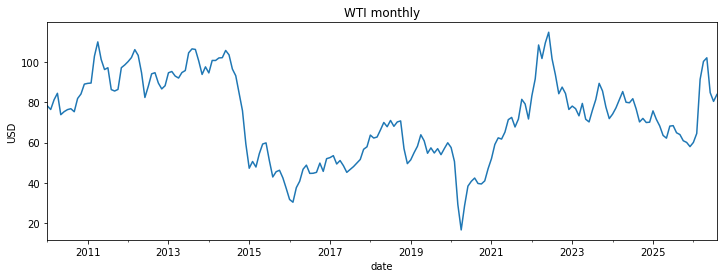

In [80]:
y = df['wti']
y.plot(figsize=(12, 4))
plt.ylabel('USD')
plt.title('WTI monthly')
plt.show()

In [82]:
# Уровень плывёт, поскольку 2014 и 2020 обвалы, а в 2022 скачок. Это не пила вокруг одного среднего. Сезон слабый.

In [83]:
train = y.iloc[:-10]
test = y.iloc[-10:]
print(train.tail())
print(test)

date
2025-06-01    68.17
2025-07-01    68.39
2025-08-01    64.86
2025-09-01    63.96
2025-10-01    60.89
Name: wti, dtype: float64
date
2025-11-01     60.06
2025-12-01     57.97
2026-01-01     60.04
2026-02-01     64.51
2026-03-01     91.38
2026-04-01    100.32
2026-05-01    102.13
2026-06-01     84.81
2026-07-01     80.46
2026-08-01     83.90
Name: wti, dtype: float64


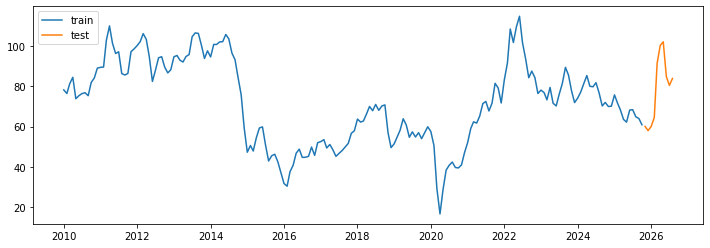

In [84]:
plt.figure(figsize=(12, 4))
plt.plot(train, label='train')
plt.plot(test, label='test')
plt.legend()
plt.show()

In [86]:
# Два теста на стационарность: ADF и KPSS.

In [87]:
adfuller(train)[1]

0.222562303644035

In [128]:
# 0.22 > 0.05 - не соответствует стационарности  

In [88]:
kpss(train)[1]

0.1

In [127]:
# 0.1 > 0.05 => стационарен

In [126]:
# Вывод: KPSS не отверг стационарность, ADF не отверг корень, тесты спорят. По графику берём разность.

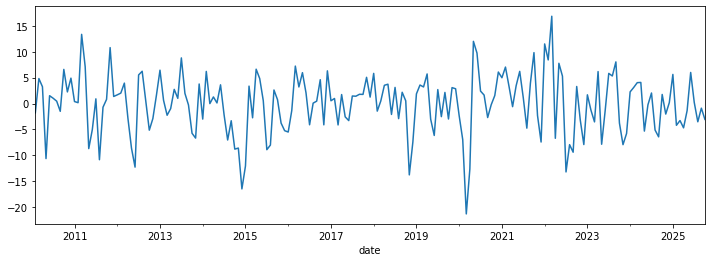

In [89]:
y_d1 = train.diff().dropna()
y_d1.plot(figsize=(12, 4))
plt.show()

In [90]:
adfuller(y_d1)[1]

2.3562228502057493e-16

In [91]:
kpss(y_d1)[1]

0.1

In [ ]:
# Тесты на стационарность соблюдены

In [ ]:
# Два способа на автокорреляцию: Ljung-Box и графики ACF/PACF.

In [93]:
print(acorr_ljungbox(train, return_df=True, lags=[6, 12, 24]))

        lb_stat      lb_pvalue
6    831.218062  2.765165e-176
12  1275.962270  7.526329e-266
24  1475.844174  3.005959e-297


In [94]:
print(acorr_ljungbox(y_d1, return_df=True, lags=[6, 12, 24]))

      lb_stat  lb_pvalue
6   16.933497   0.009531
12  18.177361   0.110410
24  39.743397   0.022783


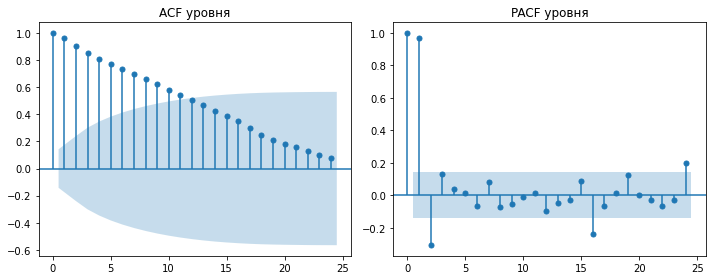

In [95]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(train, ax=ax[0], lags=24)
plot_pacf(train, ax=ax[1], lags=24)
ax[0].set_title('ACF уровня')
ax[1].set_title('PACF уровня')
plt.tight_layout()
plt.show()

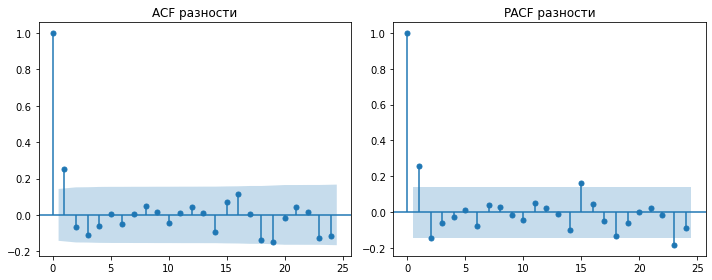

In [96]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(y_d1, ax=ax[0], lags=24)
plot_pacf(y_d1, ax=ax[1], lags=24)
ax[0].set_title('ACF разности')
ax[1].set_title('PACF разности')
plt.tight_layout()
plt.show()

In [97]:
print('AR(1) ', ARIMA(y_d1, order=(1, 0, 0)).fit().aic)
print('AR(2) ', ARIMA(y_d1, order=(2, 0, 0)).fit().aic)
print('MA(1) ', ARIMA(y_d1, order=(0, 0, 1)).fit().aic)
print('ARMA(1,1) ', ARIMA(y_d1, order=(1, 0, 1)).fit().aic)

AR(1)  1187.7296219490831
AR(2)  1185.8521557977697
MA(1)  1185.2403880007605
ARMA(1,1)  1187.158106340198


In [98]:
arma = ARIMA(y_d1, order=(0, 0, 1)).fit()
print(arma.summary())

                               SARIMAX Results                                
Dep. Variable:                    wti   No. Observations:                  189
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -589.620
Date:                Thu, 24 Sep 2026   AIC                           1185.240
Time:                        09:35:36   BIC                           1194.966
Sample:                    02-01-2010   HQIC                          1189.180
                         - 10-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1004      0.536     -0.187      0.851      -1.150       0.949
ma.L1          0.2944      0.070      4.220      0.000       0.158       0.431
sigma2        29.9945      2.664     11.259      0.0

In [99]:
print(acorr_ljungbox(arma.resid.dropna(), return_df=True, lags=[6, 12]))

     lb_stat  lb_pvalue
6   3.194391   0.784083
12  4.378515   0.975598


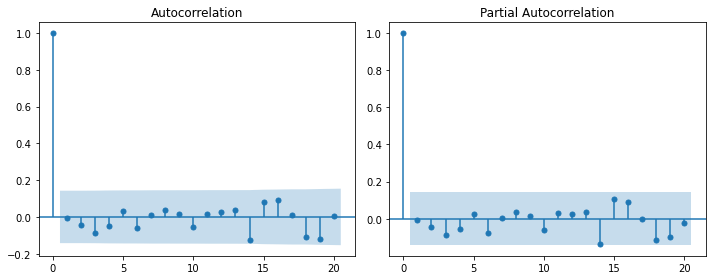

In [100]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(arma.resid.dropna(), ax=ax[0], lags=20)
plot_pacf(arma.resid.dropna(), ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

In [101]:
fc_d = arma.forecast(steps=10)
arma_oos = train.iloc[-1] + np.cumsum(fc_d.values)
print(arma_oos)

[59.90813093 59.80774095 59.70735098 59.60696101 59.50657103 59.40618106
 59.30579109 59.20540111 59.10501114 59.00462116]


In [102]:
# MA(1) на разности лучше по AIC. Остатки тихие. Прогноз разности сложили с последним train — получили уровень.

In [103]:
## ARIMA на уровне

# Ряд изначально нестационарный, поэтому ARIMA с d = 1.

In [104]:
print('ARIMA(1,1,0)', ARIMA(train, order=(1, 1, 0)).fit().aic)
print('ARIMA(0,1,1)', ARIMA(train, order=(0, 1, 1)).fit().aic)
print('ARIMA(1,1,1)', ARIMA(train, order=(1, 1, 1)).fit().aic)

ARIMA(1,1,0) 1185.7645490076789
ARIMA(0,1,1) 1183.278482687601
ARIMA(1,1,1) 1185.197095370889


In [105]:
res_arima = ARIMA(train, order=(0, 1, 1)).fit()
print(res_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                    wti   No. Observations:                  190
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -589.639
Date:                Thu, 24 Sep 2026   AIC                           1183.278
Time:                        09:36:34   BIC                           1189.762
Sample:                    01-01-2010   HQIC                          1185.905
                         - 10-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2945      0.068      4.358      0.000       0.162       0.427
sigma2        30.0005      2.638     11.374      0.000      24.831      35.170
Ljung-Box (L1) (Q):                   0.01   Jarque-

In [106]:
print(acorr_ljungbox(res_arima.resid.dropna(), return_df=True, lags=[6, 12]))

    lb_stat  lb_pvalue
6   2.75588   0.838803
12  3.88502   0.985423


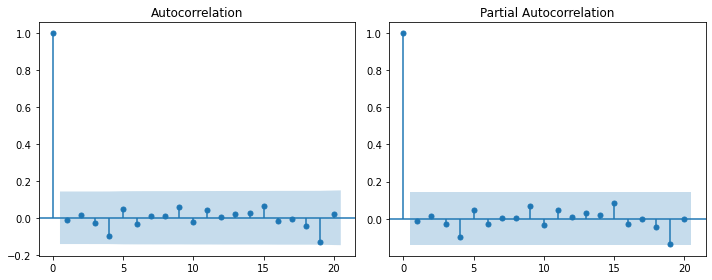

In [107]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(res_arima.resid.dropna(), ax=ax[0], lags=20)
plot_pacf(res_arima.resid.dropna(), ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

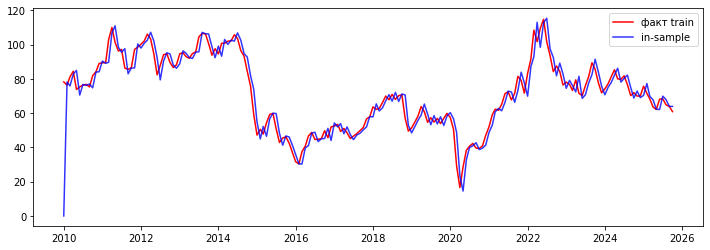

In [108]:
pred_arima = res_arima.predict()
fc_arima = res_arima.forecast(steps=10)

plt.figure(figsize=(12, 4))
plt.plot(train, color='red', label='факт train')
plt.plot(pred_arima, color='blue', alpha=0.8, label='in-sample')
plt.legend()
plt.show()

In [109]:
# ARIMA(0,1,1) чуть лучше по AIC. ma.L1 значим. Остатки белый шум. In-sample почти совпадает с фактом — так у моделей с d = 1.

In [111]:
## Регрессоры и ARIMAX

# - indpro — промпроизводство США, непрерывный. Спрос на топливо. На будущее: FRED или прогноз INDPRO.
# - dollar — индекс доллара, непрерывный. Нефть в долларах. На будущее: FRED или прогноз курса.
# - winter — ноябрь–март, dummy. Календарь, известен заранее.

# На test непрерывные берём как факт, чтобы сравнить модели. Цену WTI из test модель не видит.

In [112]:
ex_tr = df[['indpro', 'dollar', 'winter']].iloc[:-10]
ex_te = df[['indpro', 'dollar', 'winter']].iloc[-10:]
ex_te

,indpro,dollar,winter
date,,,
2025-11-01,101.0344,121.417717,1
2025-12-01,101.4941,120.188323,1
2026-01-01,101.0388,119.229810,1
2026-02-01,101.9053,117.906021,1
2026-03-01,101.7336,119.919855,1
2026-04-01,102.5783,119.036318,0
2026-05-01,102.6396,118.779185,0
2026-06-01,102.8420,120.083448,0
2026-07-01,103.0454,120.597045,0


In [113]:
res_x = ARIMA(train, order=(0, 1, 1), exog=ex_tr).fit()
print(res_x.summary())

                               SARIMAX Results                                
Dep. Variable:                    wti   No. Observations:                  190
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -576.871
Date:                Thu, 24 Sep 2026   AIC                           1163.742
Time:                        09:37:22   BIC                           1179.951
Sample:                    01-01-2010   HQIC                          1170.308
                         - 10-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
indpro         0.7942      0.344      2.311      0.021       0.121       1.468
dollar        -1.1989      0.256     -4.684      0.000      -1.701      -0.697
winter        -1.0216      0.916     -1.115      0.2

In [114]:
print(acorr_ljungbox(res_x.resid.dropna(), return_df=True, lags=[6, 12]))

     lb_stat  lb_pvalue
6   0.995716   0.985774
12  1.459234   0.999887


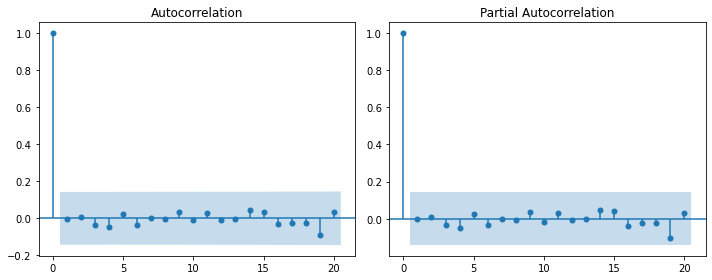

In [115]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(res_x.resid.dropna(), ax=ax[0], lags=20)
plot_pacf(res_x.resid.dropna(), ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

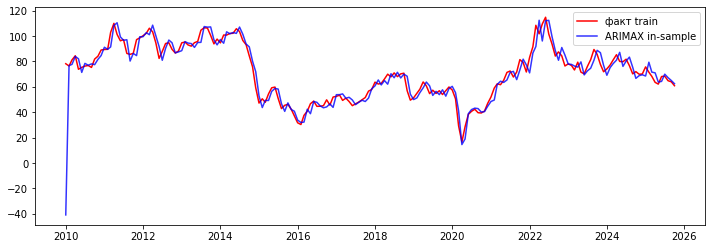

In [116]:
pred_x = res_x.predict()
fc_x = res_x.forecast(steps=10, exog=ex_te)

plt.figure(figsize=(12, 4))
plt.plot(train, color='red', label='факт train')
plt.plot(pred_x, color='blue', alpha=0.8, label='ARIMAX in-sample')
plt.legend()
plt.show()

In [117]:
# indpro и dollar значимы, winter нет. Dummy оставляем, потому что задание просит. Остатки тихие. AIC лучше, чем у чистой ARIMA.

In [118]:
## Сравнение с фактом на test

In [119]:
naive = pd.Series(train.iloc[-1], index=test.index)

cmp = pd.DataFrame({
    'fact': test,
    'naive': naive,
    'ARMA': arma_oos,
    'ARIMA': fc_arima.values,
    'ARIMAX': fc_x.values
}, index=test.index)
cmp

,fact,naive,ARMA,ARIMA,ARIMAX
date,,,,,
2025-11-01,60.06,60.89,59.908131,59.98542,58.557973
2025-12-01,57.97,60.89,59.807741,59.98542,60.397017
2026-01-01,60.04,60.89,59.707351,59.98542,61.184625
2026-02-01,64.51,60.89,59.606961,59.98542,63.459912
2026-03-01,91.38,60.89,59.506571,59.98542,60.909098
2026-04-01,100.32,60.89,59.406181,59.98542,63.660839
2026-05-01,102.13,60.89,59.305791,59.98542,64.017808
2026-06-01,84.81,60.89,59.205401,59.98542,62.614822
2026-07-01,80.46,60.89,59.105011,59.98542,62.160587


In [120]:
print('RMSE naive', np.sqrt(np.mean((cmp['fact'] - cmp['naive'])**2)))
print('RMSE ARMA', np.sqrt(np.mean((cmp['fact'] - cmp['ARMA'])**2)))
print('RMSE ARIMA', np.sqrt(np.mean((cmp['fact'] - cmp['ARIMA'])**2)))
print('RMSE ARIMAX', np.sqrt(np.mean((cmp['fact'] - cmp['ARIMAX'])**2)))

RMSE naive  23.85949748003926
RMSE ARMA   25.065375814901596
RMSE ARIMA  24.536872722662626
RMSE ARIMAX 22.2446141237325


In [121]:
print('MAE naive', np.mean(np.abs(cmp['fact'] - cmp['naive'])))
print('MAE ARMA', np.mean(np.abs(cmp['fact'] - cmp['ARMA'])))
print('MAE ARIMA', np.mean(np.abs(cmp['fact'] - cmp['ARIMA'])))
print('MAE ARIMAX', np.mean(np.abs(cmp['fact'] - cmp['ARIMAX'])))

MAE naive  18.588
MAE ARMA   19.46917214494269
MAE ARIMA  18.97566398173103
MAE ARIMAX 17.148878871305648


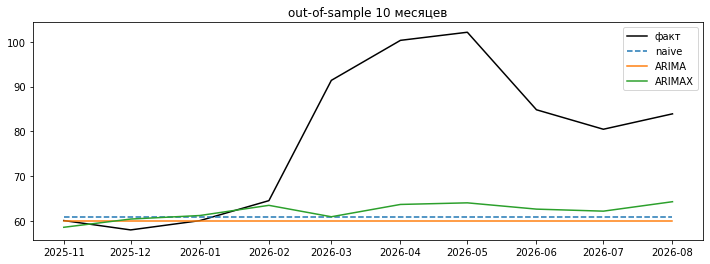

In [122]:
plt.figure(figsize=(12, 4))
plt.plot(test, color='black', label='факт')
plt.plot(cmp['naive'], ls='--', label='naive')
plt.plot(cmp['ARIMA'], label='ARIMA')
plt.plot(cmp['ARIMAX'], label='ARIMAX')
plt.legend()
plt.title('out-of-sample 10 месяцев')
plt.show()

In [123]:
## Вывод

# Показатель качества — RMSE на 10 out-of-sample месяцах.

# Почему d = 1: уровень нестационарный, одна разность стационарна.
# Почему (0,1,1): на разности ACF обрыв после лага 1, AIC лучше, чем у AR(1) и ARMA(1,1).
# Почему регрессоры: доллар и промпроизводство связаны с ценой нефти; зима — календарь.
# In-sample у всех почти совпадает с фактом, по нему модель не выбираем.

# Лучшая по RMSE test — ARIMAX(0,1,1).
# Чистая ARIMA наивную не бьёт.
# Скачок весны 2026 никто не ловит: модели остаются около последнего train (~61), факт уходит к 100. ARIMAX чуть ближе за счёт доллара и indpro, не потому что угадала шок.